## Subset selection from the 2 benchmarks

### VGGT: non-rigid / dynamic motion

- **Stated by the authors (§Limitations):** VGGT handles only "minor non-rigid motions" and "fails in scenarios involving substantial non-rigid deformation".
- **Why (our reading of the design):** VGGT is trained to predict cameras, depth and point maps for a single rigid scene in the first camera's frame. A point that moves independently has no consistent 3D position across frames. Its tracking head (CoTracker2-style) is a separate output from the geometry heads, so lifting 2D tracks to 3D can inherit inconsistencies. The paper's own dynamic tracking result (Table 8) required fine-tuning the backbone.
- **Hypothesis (H1):** accuracy drops on independently moving points compared with static points, mainly in 3D.
- **Subset:** split each benchmark by ground-truth point motion in the world frame (moving cars in DriveTrack, people in Panoptic Studio, large moving foreground in DAVIS), and apply the same split to D4RT as a comparison.

In [1]:
import torch
print("CUDA:", torch.cuda.is_available())

CUDA: True


In [9]:
from pathlib import Path
from vggt.utils.load_fn import load_and_preprocess_images

folder = Path(r"C:\Users\98910\Desktop\3\project\AML_project\images\chair")

image_paths = [str(folder / f"{i}.jpg") for i in range(1, 6)]

images = load_and_preprocess_images(image_paths)

print("Images loaded:", images.shape)

Images loaded: torch.Size([5, 3, 518, 518])


In [10]:
import torch
from vggt.models.vggt import VGGT

model = VGGT.from_pretrained("facebook/VGGT-1B")
model = model.eval().to(device="cuda", dtype=torch.float16)

print("VGGT ready on GPU!")

VGGT ready on GPU!


In [11]:
import torch

# Avoid the previous Float32 / Float16 mismatch
model = model.cpu().float()
torch.cuda.empty_cache()
model = model.to("cuda").eval()

# Test with one image first
with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.float16):
        input_images = images[:1].unsqueeze(0).to("cuda")
        predictions = model(input_images)

print("VGGT inference completed!")
print(predictions.keys())

VGGT inference completed!
dict_keys(['pose_enc', 'pose_enc_list', 'depth', 'depth_conf', 'world_points', 'world_points_conf', 'images'])


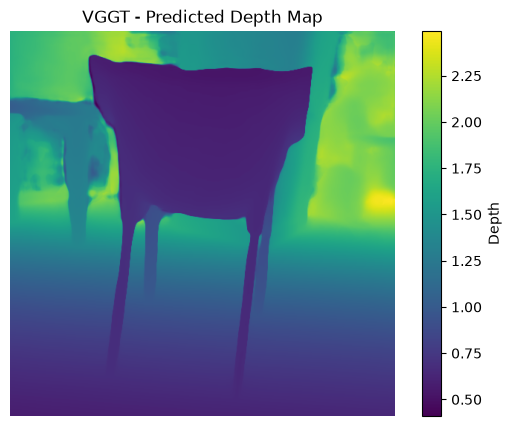

In [12]:
import matplotlib.pyplot as plt

depth = predictions["depth"][0, 0, :, :, 0]
depth = depth.float().cpu().numpy()

plt.figure(figsize=(7, 5))
plt.imshow(depth, cmap="viridis")
plt.colorbar(label="Depth")
plt.title("VGGT - Predicted Depth Map")
plt.axis("off")
plt.show()

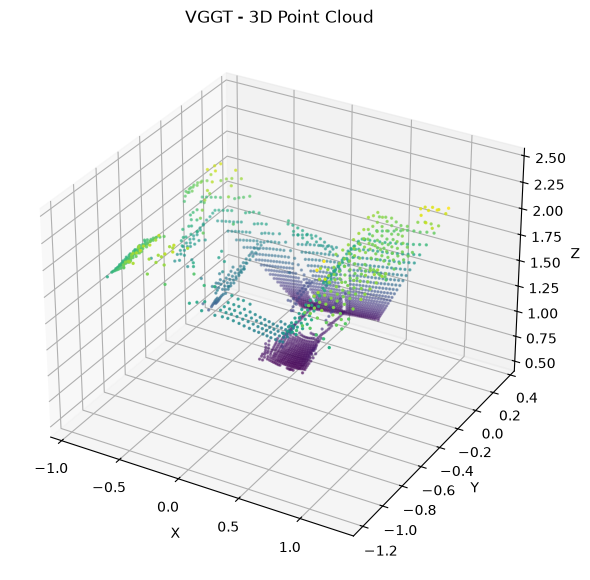

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Extract 3D points from the first image
points = predictions["world_points"][0, 0, ::12, ::12, :]
points = points.float().cpu().numpy().reshape(-1, 3)

# Remove invalid points
points = points[np.isfinite(points).all(axis=1)]

# Plot 3D point cloud
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    c=points[:, 2],
    cmap="viridis",
    s=2
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("VGGT - 3D Point Cloud")

plt.show()

### D4RT: possible limitation (inferred, not stated by the authors)

**Primary: independent queries, no temporal coupling.**
- Each query is decoded on its own through cross-attention into the scene representation (§2.2). The authors say enabling self-attention between queries caused "major performance drops", so this is a deliberate speed trade-off.
- A track is the same source point queried at every target time (`t_tgt = t_cam = 1..T`), with no correlation volume or iterative refinement as in CoTracker or TAPIR. Fine localization relies on a 9x9 RGB patch in the query (§4.4).
- Consequence (our hypothesis, not shown in the paper): nothing ties together consecutive points of the same track or points of the same moving body, so tracks may jitter or drift over time, especially on moving points and after occlusions.

**Secondary (supported by the paper): sensitivity to estimated intrinsics.**
- In Table 4 (TAPVid-3D, camera frame), AJ rises when ground-truth intrinsics are given: DriveTrack 0.257 → 0.304, ADT 0.240 → 0.307, Panoptic Studio 0.138 → 0.372.
- D4RT estimates the focal length from its own decoded points (§2.1), so this estimate is a measurable error source. It matters for our 2D adaptation when projecting 3D points to the image, but not when using the auxiliary 2D head.

*Both points still have to be confirmed on actual predictions.*

### D4RT: work needed to justify this choice

The points above come from the paper only. The task requires them to be confirmed by preliminary experiments, so each one becomes a test the team must run. Use Open-D4RT, since the original code is unavailable.

**1. Sanity check (do first)**
- Run D4RT on a few TAPVid-3D sequences (DriveTrack, ADT, Panoptic Studio).
- Compare with Table 4 of the paper. Open-D4RT is a re-implementation, so large gaps mean our observations apply to Open-D4RT, not to the original model, and the report must say so.

**2. Test the primary limitation (temporal coupling)**
- Measure frame-to-frame jitter of predicted 3D tracks (second difference of positions) against ground truth and against CoTracker3 + depth.
- Compute it separately on static and on moving points (same split as H1), and on points before and after an occlusion.
- Metrics: 3D acceleration error, AJ, APD, OA per split.

**3. Test the secondary limitation (intrinsics)**
- Run each sequence with and without ground-truth intrinsics.
- Report the AJ / APD gap per dataset and check that it matches Table 4.
- For the 2D adaptation, compare the projected 3D output with the auxiliary 2D head, to see whether focal-length error propagates.

**4. Qualitative evidence (Q2)**
- Pick at least 3 sequences with visible failures, overlay predicted and ground-truth tracks, and link each failure to the claim it supports.

**5. Decision rule (agree on it beforehand)**
- Keep a claim only if the gap is clear on several sequences, not on a single example.
- If a claim shows no measurable effect, drop it and say so. D4RT then serves as the control that holds on the dynamic subset, which supports the VGGT-based argument.

**6. What goes into the report (Q1)**
- For each retained claim: what the paper says, what we observed, and the number that quantifies it.